# Freight EDA


## Step 1: Load the data
**Why:** We need the CSV files inside pandas so we can look at them.
`train` = loads with known prices (we learn from these).
`val` = loads with hidden prices (we predict these).

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("data/train_test.csv")
val = pd.read_csv("data/validation.csv")

train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## Step 2: How big is the data and which dates does it cover?
**Why:** To know what we're working with. We also turn the `date` column into real dates
(it starts as plain text) so we can later pull out things like month and weekday.

In [14]:
train["date"] = pd.to_datetime(train["date"])
val["date"] = pd.to_datetime(val["date"])

print("Training rows and columns:", train.shape)
print("Training dates:", train["date"].min().date(), "to", train["date"].max().date())
print()
print("Validation rows and columns:", val.shape)
print("Validation dates:", val["date"].min().date(), "to", val["date"].max().date())

Training rows and columns: (48000, 14)
Training dates: 2025-01-01 to 2025-10-31

Validation rows and columns: (12000, 13)
Validation dates: 2025-11-01 to 2025-12-31


**What we see:** Training is Jan–Oct, validation is Nov–Dec.
So the model has to predict months it has never seen.

## Step 3: Column types
**Why:** To see which columns are numbers and which are text. Text columns
(like city names) need special handling before a model can use them.

In [15]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   load_id       48000 non-null  object        
 1   pickup        48000 non-null  object        
 2   delivery      48000 non-null  object        
 3   pickup_lat    48000 non-null  float64       
 4   pickup_lon    48000 non-null  float64       
 5   delivery_lat  48000 non-null  float64       
 6   delivery_lon  48000 non-null  float64       
 7   distance      48000 non-null  float64       
 8   equipment     48000 non-null  object        
 9   weight        47700 non-null  float64       
 10  date          48000 non-null  datetime64[ns]
 11  market_index  47626 non-null  float64       
 12  quote_signal  48000 non-null  float64       
 13  posted_rate   48000 non-null  float64       
dtypes: datetime64[ns](1), float64(9), object(4)
memory usage: 5.1+ MB


## Step 4: Missing values
**Why:** A model can't learn from empty cells. We need to know how many there are so we can fill them later.

In [16]:
print("Missing in training:")
print(train.isna().sum())

Missing in training:
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64


In [17]:
print("Missing in validation:")
print(val.isna().sum())

Missing in validation:
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64


**What we see:** `weight` and `market_index` have some empty cells, in both files.

## Step 5: Duplicates
**Why:** If the same load is in the data twice, the model counts it twice.
We ignore `load_id` because every row has a different ID anyway.

In [18]:
duplicates = train.drop(columns="load_id").duplicated().sum()
print("Duplicate loads:", duplicates)

Duplicate loads: 0


## Step 6: Basic statistics
**Why:** The min and max of each column quickly show impossible values.

In [19]:
train.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,48000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,2025-05-31 19:53:29.400000,1.083387,2.062468,2373.980682
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,2025-01-01 00:00:00,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,2025-03-18 00:00:00,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,2025-05-31 00:00:00,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,2025-08-15 00:00:00,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,2025-10-31 00:00:00,1.467780,3.610350,25533.000000
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,NaN,0.168091,0.291391,1486.493245


**What we see:** `weight` has a negative minimum. A load can't weigh less than zero.

## Step 7: Negative weights
**Why:** Negative weight is impossible. If the negative numbers look like normal weights with a
minus sign in front, it's just a typo and we can make them positive.

In [20]:
negative = train[train["weight"] < 0]
positive = train[train["weight"] > 0]

print("Negative weights in training:", len(negative))
print("Negative weights in validation:", len(val[val["weight"] < 0]))
print()
print("Normal weights:")
print(positive["weight"].describe())
print()
print("Negative weights with the minus sign removed:")
print(negative["weight"].abs().describe())

Negative weights in training: 292
Negative weights in validation: 145

Normal weights:
count    47408.000000
mean     31415.358674
std       7994.902979
min       5000.000000
25%      25922.000000
50%      31493.500000
75%      37063.000000
max      47500.000000
Name: weight, dtype: float64

Negative weights with the minus sign removed:
count      292.000000
mean     31724.195205
std       8262.536326
min       5000.000000
25%      25928.500000
50%      31821.500000
75%      37284.250000
max      47500.000000
Name: weight, dtype: float64


**What we see:** Both look the same, so the minus sign is a typo. Fix: make them positive.

In [21]:
print("Loads with weight exactly 47,500:", len(train[train["weight"] == 47500]))

Loads with weight exactly 47,500: 1191


**What we see:** Many loads sit exactly at 47,500, which looks like a maximum cap.

## Step 8: Price per mile
**Why:** A $2,000 load is cheap for 1,000 miles but expensive for 100 miles.
Dividing price by distance lets us compare loads fairly and spot strange prices.

In [22]:
train["rate_per_mile"] = train["posted_rate"] / train["distance"]
train["rate_per_mile"].describe()

count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
25%          1.986974
50%          2.145348
75%          2.342696
max         14.125294
Name: rate_per_mile, dtype: float64

## Step 9: Look at the spread of prices
**Why:** A histogram shows where most prices sit and how far the strange ones go.

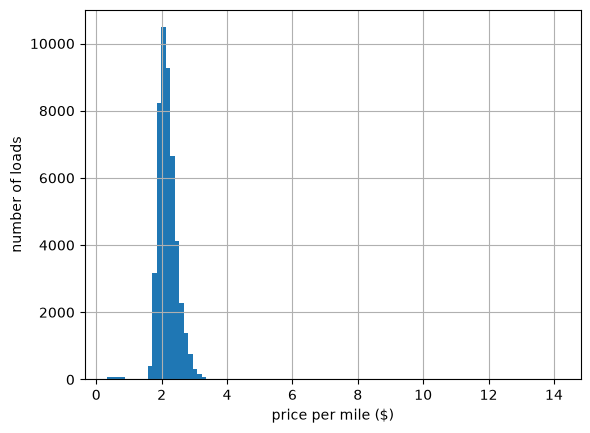

In [23]:
train["rate_per_mile"].hist(bins=100)
plt.xlabel("price per mile ($)")
plt.ylabel("number of loads")
plt.show()

**What we see:** Almost all loads are around $2 per mile, with a few far away from that.

## Step 10: Outliers (strange prices)
**Why:** Prices like $0.30 or $14 per mile are probably data errors. If we train on them,
they confuse the model. We count them here and remove them from training later.

In [24]:
too_low = train[train["rate_per_mile"] < 0.5]
too_high = train[train["rate_per_mile"] > 10]

print("Loads under $0.50 per mile:", len(too_low))
print("Loads over $10 per mile:", len(too_high))

Loads under $0.50 per mile: 103
Loads over $10 per mile: 49


In [25]:
columns = ["pickup", "delivery", "distance", "equipment", "posted_rate", "rate_per_mile"]
print("Lowest examples:")
print(too_low[columns].head())
print()
print("Highest examples:")
print(too_high[columns].head())

Lowest examples:
          pickup      delivery  distance equipment  posted_rate  rate_per_mile
508    Las Vegas  Grand Rapids    1976.4   Flatbed       699.41       0.353881
872   Cincinnati     Lexington     144.0   Dry Van        67.80       0.470833
1027      Dallas    Fort Wayne     970.6   Dry Van       473.34       0.487678
1555     El Paso      New York    2415.0   Dry Van       911.44       0.377408
2268     Atlanta    Providence    1137.6    Reefer       543.71       0.477945

Highest examples:
          pickup     delivery  distance equipment  posted_rate  rate_per_mile
870        Tulsa  Baton Rouge     305.6    Reefer      4069.24      13.315576
1415  Montgomery   Birmingham     198.2    Reefer      2509.96      12.663774
2469      Tucson  Albuquerque     441.5   Flatbed      4989.66      11.301608
4489      Dayton   Harrisburg     476.7   Dry Van      5048.45      10.590413
6078  Cincinnati    Lexington     150.4    Reefer      1550.14      10.306782


## Step 11: Equipment (trailer type)
**Why:** Different trailers cost different amounts. A refrigerated trailer (Reefer) should cost more.
We use the median (middle value) because outliers don't pull it around.

In [26]:
print(train["equipment"].value_counts())
print()
print("Median price per mile:")
print(train.groupby("equipment")["rate_per_mile"].median())

equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

Median price per mile:
equipment
Dry Van    2.046203
Flatbed    2.219683
Reefer     2.311540
Name: rate_per_mile, dtype: float64


**What we see:** Dry Van is cheapest, then Flatbed, then Reefer.

## Step 12: Cities
**Why:** If validation has cities the model never saw in training, it can't learn anything about
those city names. It would have to rely on other columns like coordinates and distance.

In [27]:
train_cities = set(train["pickup"]) | set(train["delivery"])
val_cities = set(val["pickup"]) | set(val["delivery"])
new_cities = val_cities - train_cities

print("Cities in training:", len(train_cities))
print("Cities in validation but NOT in training:", new_cities)

rows_with_new_city = val[val["pickup"].isin(new_cities) | val["delivery"].isin(new_cities)]
print("Validation loads that use one of these cities:", len(rows_with_new_city), "out of", len(val))

Cities in training: 64
Cities in validation but NOT in training: {'Norfolk', 'San Diego', 'Jackson', 'Allentown', 'Laredo', 'Chicago', 'Charlotte', 'Knoxville'}
Validation loads that use one of these cities: 1447 out of 12000


**What we see:** 8 new cities, used by about 12% of validation loads.

## Step 13: Which numbers are linked to price?
**Why:** Correlation measures how strongly two columns move together.
Close to 1 = strong link. Close to 0 = no link. We remove the strange prices first so they don't distort this.

In [28]:
clean = train[(train["rate_per_mile"] >= 0.5) & (train["rate_per_mile"] <= 10)]

clean[["distance", "weight", "market_index", "quote_signal", "posted_rate", "rate_per_mile"]].corr().round(2)

,distance,weight,market_index,quote_signal,posted_rate,rate_per_mile
distance,1.00,0.00,-0.00,-0.06,0.92,-0.38
weight,0.00,1.00,-0.00,0.01,0.03,0.09
market_index,-0.00,-0.00,1.00,-0.07,0.03,0.09
quote_signal,-0.06,0.01,-0.07,1.00,-0.04,0.06
posted_rate,0.92,0.03,0.03,-0.04,1.00,-0.05
rate_per_mile,-0.38,0.09,0.09,0.06,-0.05,1.00


**What we see:** Distance is strongly linked to total price (0.92). Longer trips cost a bit less **per mile** (−0.38).
Other columns have weak direct links, but they might still help the model in combination.

## Step 14: Price vs distance
**Why:** A picture to confirm that longer trips cost more. We plot 3,000 random loads so the chart stays readable.

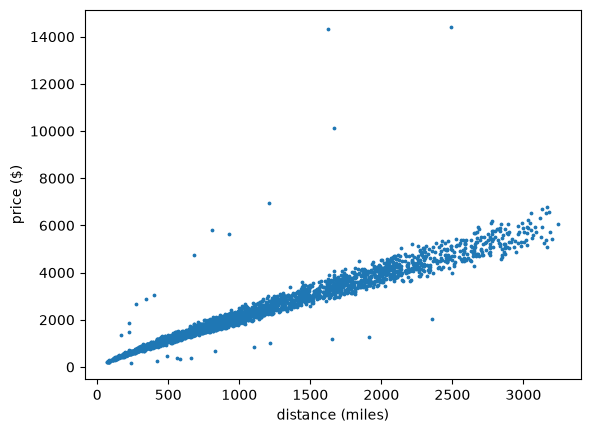

In [29]:
sample = clean.sample(3000, random_state=1)

plt.scatter(sample["distance"], sample["posted_rate"], s=3)
plt.xlabel("distance (miles)")
plt.ylabel("price ($)")
plt.show()

## Step 15: What is `quote_signal`?
**Why:** Its numbers (around 2) look a lot like price per mile. If it's basically a price estimate,
it will be one of the most useful columns for the model.

In [30]:
ratio = clean["quote_signal"] / clean["rate_per_mile"]
print("Median of quote_signal / price per mile:", round(ratio.median(), 3))

close = ratio[(ratio > 0.9) & (ratio < 1.1)]
print("Share of loads where they are within 10% of each other:", round(len(close) / len(ratio), 2))

Median of quote_signal / price per mile: 0.996
Share of loads where they are within 10% of each other: 0.67


**What we see:** For most loads `quote_signal` is very close to the real price per mile.

## Step 16: Price across the year
**Why:** To see if prices go up or down over time. This matters because we predict Nov–Dec.

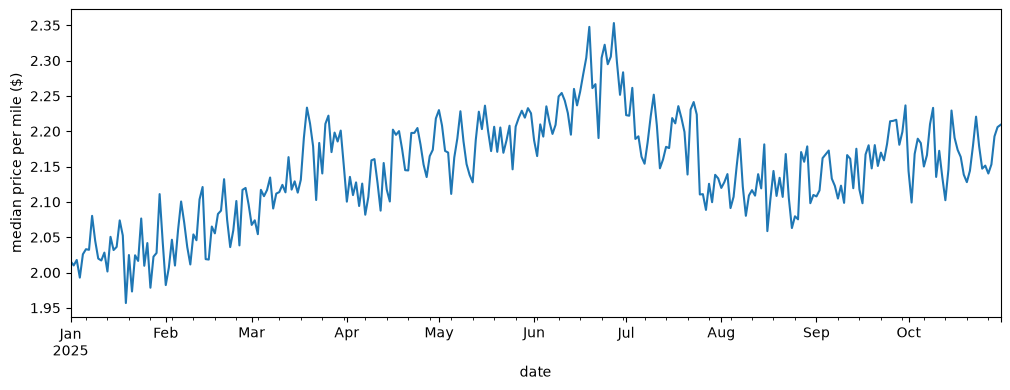

In [31]:
daily = train.groupby("date")["rate_per_mile"].median()

daily.plot(figsize=(12, 4))
plt.ylabel("median price per mile ($)")
plt.show()

In [32]:
train["month"] = train["date"].dt.month
train.groupby("month")["rate_per_mile"].median()

month
1     2.029158
2     2.061143
3     2.139279
4     2.146699
5     2.190194
6     2.247885
7     2.187422
8     2.120525
9     2.159622
10    2.163828
Name: rate_per_mile, dtype: float64

**What we see:** Prices rise from January to June, then come down a bit (about a 10% swing).
We **can't** give the model "month" directly, because it has never seen months 11 and 12.

## Step 17: Day of week
**Why:** To check if some weekdays are more expensive. 0 = Monday … 6 = Sunday.

In [33]:
train["day_of_week"] = train["date"].dt.dayofweek
train.groupby("day_of_week")["rate_per_mile"].median()

day_of_week
0    2.126141
1    2.139350
2    2.163024
3    2.170587
4    2.157178
5    2.131724
6    2.127364
Name: rate_per_mile, dtype: float64

**What we see:** Only about a 2% difference. Midweek is slightly more expensive.

## Step 18: Day of month
**Why:** To check if prices change from the start to the end of a month.

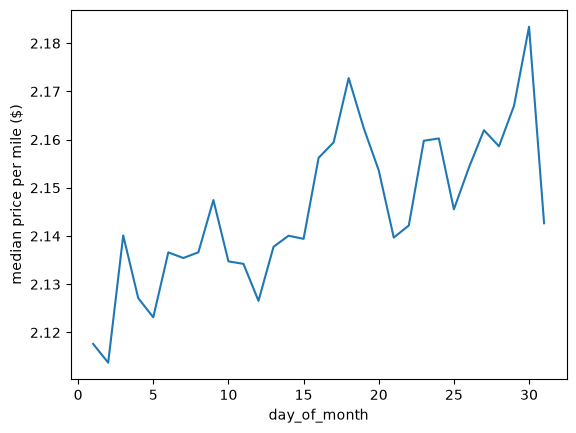

In [34]:
train["day_of_month"] = train["date"].dt.day
train.groupby("day_of_month")["rate_per_mile"].median().plot()
plt.ylabel("median price per mile ($)")
plt.show()

**What we see:** A small rise toward the end of the month (about 2%).

## Step 19: Holidays
**Why:** November–December have Thanksgiving and Christmas. If holidays changed prices in
training, we'd want the model to know about them.

In [35]:
holidays = ["2025-01-01", "2025-05-26", "2025-07-04", "2025-09-01"]
monthly = train.groupby("month")["rate_per_mile"].median()

for day in holidays:
    month = pd.to_datetime(day).month
    print(day, "holiday:", round(daily.loc[day], 3), "| month median:", round(monthly.loc[month], 3))

2025-01-01 holiday: 2.016 | month median: 2.029
2025-05-26 holiday: 2.207 | month median: 2.19
2025-07-04 holiday: 2.189 | month median: 2.187
2025-09-01 holiday: 2.108 | month median: 2.16


**What we see:** Holiday prices are close to normal, so there's no clear holiday effect.

## Step 20: Does `market_index` follow the price pattern?
**Why:** We can't use "month" as a feature. But if `market_index` rises and falls with prices,
the model can follow the season through it, and `market_index` exists for Nov–Dec.

In [36]:
train.groupby("month")[["rate_per_mile", "market_index"]].median()

,rate_per_mile,market_index
month,,
1,2.029158,0.932905
2,2.061143,0.993130
3,2.139279,1.064850
4,2.146699,1.207125
5,2.190194,1.304025
6,2.247885,1.275130
7,2.187422,1.212100
8,2.120525,0.982340
9,2.159622,0.887810


In [37]:
train.groupby("day_of_week")[["rate_per_mile", "market_index"]].median()

,rate_per_mile,market_index
day_of_week,,
0,2.126141,0.95966
1,2.139350,1.03507
2,2.163024,1.10820
3,2.170587,1.13529
4,2.157178,1.08602
5,2.131724,1.00467
6,2.127364,0.94399


**What we see:** By weekday, `market_index` matches prices closely (both peak midweek).
By month it follows prices roughly, not perfectly (it rises Jan to May like prices, but September is low while prices stay high).
So it carries a good part of the time pattern, but not all of it.

## Step 21: Is validation similar to training?
**Why:** If Nov–Dec look very different from Jan–Oct, the model will have a harder time.

In [38]:
for column in ["distance", "weight", "market_index", "quote_signal"]:
    print(column, "| train median:", round(train[column].median(), 3), "| val median:", round(val[column].median(), 3))

distance | train median: 953.3 | val median: 953.6
weight | train median: 31436.5 | val median: 31193.0
market_index | train median: 1.056 | val median: 0.923
quote_signal | train median: 2.056 | val median: 2.051


In [39]:
print("Training equipment mix:")
print(train["equipment"].value_counts(normalize=True).round(2))
print()
print("Validation equipment mix:")
print(val["equipment"].value_counts(normalize=True).round(2))

Training equipment mix:
equipment
Dry Van    0.57
Reefer     0.25
Flatbed    0.18
Name: proportion, dtype: float64

Validation equipment mix:
equipment
Dry Van    0.56
Reefer     0.25
Flatbed    0.18
Name: proportion, dtype: float64


**What we see:** Very similar, except `market_index` is lower in Nov–Dec (a quieter market).

## Step 22: What we need for the December chart
**Why:** The December file has no `market_index` or `quote_signal`. But validation has
December loads, so we can take each day's average and use that.

In [40]:
december = val[val["date"].dt.month == 12]
print("December loads in validation:", len(december))

december_daily = december.groupby("date")[["market_index", "quote_signal"]].mean()
december_daily.head(10)

December loads in validation: 6164


,market_index,quote_signal
date,,
2025-12-01,0.834919,2.052023
2025-12-02,0.914680,2.034115
2025-12-03,0.994063,2.053293
2025-12-04,1.024021,2.065683
2025-12-05,0.975120,2.047368
2025-12-06,0.889154,2.025273
2025-12-07,0.830590,2.050358
2025-12-08,0.840110,2.039962
2025-12-09,0.917263,2.050095


In [41]:
lexington = train[(train["pickup"] == "Lexington") & (train["delivery"] == "Fort Wayne")]
print("Lexington to Fort Wayne loads in training:", len(lexington))
print(lexington.groupby("equipment")["posted_rate"].median())

Lexington to Fort Wayne loads in training: 32
equipment
Dry Van    807.89
Flatbed    877.84
Reefer     934.50
Name: posted_rate, dtype: float64


## Summary

**Data problems found (and the planned fix)**
- Missing `weight` and `market_index` → fill them in.
- Negative weights → minus-sign typo, make them positive.
- Strange prices (under $0.50 or over $10 per mile) → remove from training only. Never remove validation rows.
- 8 cities in validation never appear in training → rely on coordinates and distance, not just city names.

**What drives price**
- Distance (by far the biggest).
- Equipment: Dry Van < Flatbed < Reefer.
- `quote_signal` is close to the real price per mile → very useful.

**Time**
- About a 10% swing across the year. Day of week and day of month only about 2%. No clear holiday effect.
- We can't use "month", but `market_index` follows a good part of the time pattern, so the model can use it instead.

**December chart**
- Fill `market_index` and `quote_signal` with each December day's average from validation.